## Transformer Language Models

### 1. Environment and Configuration

In [69]:
# Import libraries for transformer language modeling
import torch # Pytorch, machine-learning framework
import torch.nn as nn # neural network tools (components)
import torch.nn.functional as F # neural network mathematical functions (operations)

import sentencepiece as spm # for BPE tokenizers
import json # for datafiles

from pathlib import Path # filepath tool

import matplotlib.pyplot as plt 

### 2. Transformer Architecture

#### 2.1 Model Configuration

In [76]:
# Shared Transformer architecture configuration
MODEL_CONFIG = { # dictionary of transformer hyperparameters
    "d_model": 256, # 256 dimensions per vector (token representation)
    "n_heads": 4, # 4 attention heads
    "n_layers": 2, # 2 transformer layers
    "d_ff": 1024, # 1024 feed forward dimension
    "dropout": 0.10, # 10% dropout
    "context_length": 128, # maximum sequence length of 128 tokens
}

print("Transformer configuration:") # print label
for parameter, value in MODEL_CONFIG.items(): # iterate over keys and values in MODEL_CONFIG dictionary
    print(f"{parameter}: {value}") # for each entry print label and value

Transformer configuration:
d_model: 256
n_heads: 4
n_layers: 2
d_ff: 1024
dropout: 0.1
context_length: 128


#### 2.2 Transformer Model Implementation

In [77]:
# Define the Transformer language model
class TransformerLM(nn.Module): # create transformer/neural network class

    def __init__(self, vocab_size, config): # initialize the model with parameters including vocabulary size and hyperparameters
        super().__init__() # initialize neural network from Pytorch

        d_model = config["d_model"] # set dimensions for token representation (retrieved from above dictionary)
        context_length = config["context_length"] # set sequence length (retrieved from above dictionary)

        self.token_embedding = nn.Embedding(vocab_size, d_model) # embed tokens from input token IDs with vocabulary model size and dimensions set above

        # Learn a vector representation for each position
        self.position_embedding = nn.Embedding(context_length, d_model) # positional embeddings using sequence length and dimensions set above

        # Create one Transformer layer
        encoder_layer = nn.TransformerEncoderLayer( # create transformer layer via Pytorch; hyperparameters below
            d_model=d_model, # set dimensions for token representation (retrieved from above dictionary)
            nhead=config["n_heads"], # set number of attention heads (retrieved from above dictionary)
            dim_feedforward=config["d_ff"], # set feed forward dimension (retrieved from above dictionary)
            dropout=config["dropout"], # set dropout (retrieved from above dictionary)
            activation="gelu", # nonlinear activation (GELU)
            batch_first=True, # input data organization (batch, sequence, features)
            norm_first=True # pre-layer normalization (prior to attention/feed-forward)
        )

        # Stack two Transformer layers
        self.transformer = nn.TransformerEncoder( # create hidden layers via Pytorch; hyperparameters below
            encoder_layer, # input from transformer layer
            num_layers=config["n_layers"], # set transformer layers (retrieved from above dictionary)
            enable_nested_tensor=False # variable length sequence optimization disabled
        )

        self.final_norm = nn.LayerNorm(d_model) # normalize token representations utilizing determined dimensions (retrieved from above dictionary)

        # Convert token representations into vocabulary prediction scores
        self.output_layer = nn.Linear(d_model, vocab_size) # convert dimensional representations to prediction scores

    # Define how input data moves through the model
    def forward(self, input_ids): # define action of transformer using token IDs

        # Get the dimensions of the input
        batch_size, seq_len = input_ids.shape # shape of input: (batch, sequence length)

        # Create position IDs for each token
        positions = torch.arange( # create position numbers
            seq_len, # sequence length
            device=input_ids.device # use same device as input data
        )

        # Look up token and positional embeddings
        token_embeddings = self.token_embedding(input_ids) # retreive token embeddings of input data
        position_embeddings = self.position_embedding(positions) # retrieve position embeddings from above 

        # Combine token information with position information
        x = token_embeddings + position_embeddings # combine token and positional embeddings

        # Create a causal attention mask
        causal_mask = torch.triu( # keep upper triangular portion of grid (triu = 'triangular upper')
            torch.ones( # create grid of ones
                seq_len, # first dimension of grid
                seq_len, # second dimension of grid
                device=input_ids.device, # use same device as input data
                dtype=torch.bool # create boolean values (boolean mask: false = attention permitted, true = attention blocked)
            ),
            diagonal=1 # start upper triangle 1 position above main diagonal
        )

        # Process embeddings through Transformer layers using causal attention
        x = self.transformer(x, mask=causal_mask) # input combined token and positional embeddings ('x') through transformer; enable causal mask
        x = self.final_norm(x) # final layer normalization (scale adjustment) of updated representations
        logits = self.output_layer(x) # convert combined representations into vocabulary prediction scores

        return logits # return prediction scores

### 3. Training Data Pipeline

#### 3.1 Data Paths and Tokenizer Loading

In [56]:
# Define paths relative to the project directory
PROJECT_DIR = Path.cwd().parent

DATA_DIR = Path("/srv/data/lt2326-h26/a1")
TOKENIZER_DIR = PROJECT_DIR / "models" / "tokenizers"

# Define training and validation files
train_files = {
    "en": DATA_DIR / "train" / "en.txt",
    "tr": DATA_DIR / "train" / "tr.txt",
    "zh": DATA_DIR / "train" / "zh.txt"
}

valid_files = {
    "en": DATA_DIR / "valid" / "en.txt",
    "tr": DATA_DIR / "valid" / "tr.txt",
    "zh": DATA_DIR / "valid" / "zh.txt"
}


In [57]:
# Load saved character-level vocabulary
with open(TOKENIZER_DIR / "character_vocab.json", "r", encoding="utf-8") as f:
    char_vocab = json.load(f)

char_to_id = char_vocab["char_to_id"]
char_unk_id = char_vocab["unk_id"]

# Load saved BPE tokenizers
bpe_small = spm.SentencePieceProcessor(
    model_file=str(TOKENIZER_DIR / "bpe_2000.model")
)

bpe_large = spm.SentencePieceProcessor(
    model_file=str(TOKENIZER_DIR / "bpe_10000.model")
)

#### 3.2 Text Loading and Tokenization

In [42]:
# Load training and validation sentences for each language
def load_sentences(file_paths):
    sentences = {}

    for lang, path in file_paths.items():
        with open(path, "r", encoding="utf-8") as f:
            sentences[lang] = [
                line.strip()
                for line in f
                if line.strip()
            ]

    return sentences


# Load multilingual datasets
train_texts = load_sentences(train_files)
valid_texts = load_sentences(valid_files)

# Verify sentence counts
for lang in train_texts:
    print(
        f"{lang}: "
        f"{len(train_texts[lang]):,} training sentences, "
        f"{len(valid_texts[lang]):,} validation sentences"
    )

en: 36,004 training sentences, 4,540 validation sentences
tr: 30,379 training sentences, 3,735 validation sentences
zh: 75,962 training sentences, 9,554 validation sentences


#### 3.3 Token Encoding, Dataset Construction, and Batching

In [59]:
# Convert sentences into token IDs using the selected tokenizer
def encode_sentences(texts, tokenizer_type):

    encoded = {}

    for lang, sentences in texts.items():

        if tokenizer_type == "character":
            encoded[lang] = [
                [char_to_id.get(char, char_unk_id) for char in sentence]
                for sentence in sentences
            ]

        elif tokenizer_type == "bpe_2000":
            encoded[lang] = [
                bpe_small.encode(sentence, out_type=int)
                for sentence in sentences
            ]

        elif tokenizer_type == "bpe_10000":
            encoded[lang] = [
                bpe_large.encode(sentence, out_type=int)
                for sentence in sentences
            ]

        else:
            raise ValueError(f"Unknown tokenizer: {tokenizer_type}")

    return encoded

In [61]:
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence


class LanguageModelDataset(Dataset):

    def __init__(self, encoded_sentences, context_length=128):

        self.examples = []

        for lang, sentences in encoded_sentences.items():

            for tokens in sentences:

                # Need at least two tokens for next-token prediction
                if len(tokens) < 2:
                    continue

                # Create consecutive chunks with overlapping boundaries
                for start in range(0, len(tokens) - 1, context_length):

                    y = tokens[start + 1:start + context_length + 1]
                    x = tokens[start:start + context_length][:len(y)]

                    self.examples.append((
                        torch.tensor(x, dtype=torch.long),
                        torch.tensor(y, dtype=torch.long)
                    ))

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        return self.examples[index]

In [62]:
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence


class LanguageModelDataset(Dataset):

    def __init__(self, encoded_sentences, context_length=128):

        self.examples = []

        for lang, sentences in encoded_sentences.items():

            for tokens in sentences:

                # Need at least two tokens for next-token prediction
                if len(tokens) < 2:
                    continue

                # Create consecutive chunks with shifted targets
                for start in range(0, len(tokens) - 1, context_length):

                    y = tokens[start + 1:start + context_length + 1]
                    x = tokens[start:start + context_length][:len(y)]

                    self.examples.append((
                        torch.tensor(x, dtype=torch.long),
                        torch.tensor(y, dtype=torch.long)
                    ))

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        return self.examples[index]

In [63]:
def collate_lm_batch(batch):

    inputs, targets = zip(*batch)

    # Pad input sequences with token ID 0
    padded_inputs = pad_sequence(
        inputs,
        batch_first=True,
        padding_value=0
    )

    # Pad target sequences with -100 (ignored by loss function)
    padded_targets = pad_sequence(
        targets,
        batch_first=True,
        padding_value=-100
    )

    return padded_inputs, padded_targets

#### 3.4 Training and Validation Dataset Preparation

In [64]:
# Prepare datasets for all three tokenizers
tokenizer_names = ["character", "bpe_2000", "bpe_10000"]

train_datasets = {}
valid_datasets = {}

for name in tokenizer_names:
    print(f"Preparing {name}...", flush=True)

    train_encoded = encode_sentences(train_texts, name)
    valid_encoded = encode_sentences(valid_texts, name)

    train_datasets[name] = LanguageModelDataset(
        train_encoded,
        context_length=MODEL_CONFIG["context_length"]
    )

    valid_datasets[name] = LanguageModelDataset(
        valid_encoded,
        context_length=MODEL_CONFIG["context_length"]
    )

    print(
        f"  Training examples: {len(train_datasets[name]):,}"
        f" | Validation examples: {len(valid_datasets[name]):,}",
        flush=True
    )

    del train_encoded, valid_encoded

print("\nAll datasets prepared.")

Preparing character...
  Training examples: 154,821 | Validation examples: 19,349
Preparing bpe_2000...
  Training examples: 143,641 | Validation examples: 17,985
Preparing bpe_10000...
  Training examples: 142,537 | Validation examples: 17,852

All datasets prepared.


### 4. Model Training

#### 4.1 Training Configuration

In [65]:
# Shared training settings
TRAIN_CONFIG = {
    "batch_size": 32,
    "learning_rate": 0.0003,
    "epochs": 3,
    "weight_decay": 0.01,
    "seed": 42,
}

# Select GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training device:", device)
print("Training configuration:", TRAIN_CONFIG)

Training device: cuda
Training configuration: {'batch_size': 32, 'learning_rate': 0.0003, 'epochs': 3, 'weight_decay': 0.01, 'seed': 42}


#### 4.2 Training the Three Transformer Models

In [67]:
import time
import math

# Directory for trained models and results
OUTPUT_DIR = PROJECT_DIR / "models" / "language_models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Vocabulary sizes for the three conditions
vocab_sizes = {
    "character": 9443,
    "bpe_2000": 2000,
    "bpe_10000": 10000
}

# Store training histories
training_histories = {}

# Train each tokenizer condition
for name in tokenizer_names:

    print(f"\n{'=' * 50}", flush=True)
    print(f"TRAINING MODEL: {name}", flush=True)
    print(f"{'=' * 50}", flush=True)

    # Reproducible initialization
    torch.manual_seed(TRAIN_CONFIG["seed"])
    torch.cuda.manual_seed_all(TRAIN_CONFIG["seed"])

    # Create a fresh model
    model = TransformerLM(
        vocab_size=vocab_sizes[name],
        config=MODEL_CONFIG
    ).to(device)

    # Count trainable parameters
    parameter_count = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )

    print(f"Trainable parameters: {parameter_count:,}", flush=True)

    # Create training and validation loaders
    train_loader = DataLoader(
        train_datasets[name],
        batch_size=TRAIN_CONFIG["batch_size"],
        shuffle=True,
        collate_fn=collate_lm_batch
    )

    valid_loader = DataLoader(
        valid_datasets[name],
        batch_size=TRAIN_CONFIG["batch_size"],
        shuffle=False,
        collate_fn=collate_lm_batch
    )

    # Optimizer
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=TRAIN_CONFIG["learning_rate"],
        weight_decay=TRAIN_CONFIG["weight_decay"]
    )

    history = {
        "train_loss": [],
        "valid_loss": [],
        "parameter_count": parameter_count
    }

    model_start = time.perf_counter()

    for epoch in range(TRAIN_CONFIG["epochs"]):

        # TRAINING
        model.train()
        train_loss_sum = 0.0
        train_tokens = 0

        for batch_idx, (inputs, targets) in enumerate(train_loader):

            inputs = inputs.to(device)
            targets = targets.to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = model(inputs)

            loss = F.cross_entropy(
                logits.reshape(-1, vocab_sizes[name]),
                targets.reshape(-1),
                ignore_index=-100
            )

            loss.backward()
            optimizer.step()

            # Weight loss by number of actual target tokens
            n_tokens = (targets != -100).sum().item()
            train_loss_sum += loss.item() * n_tokens
            train_tokens += n_tokens

            if (batch_idx + 1) % 500 == 0:
                print(
                    f"Epoch {epoch + 1}/{TRAIN_CONFIG['epochs']} | "
                    f"Batch {batch_idx + 1}/{len(train_loader)} | "
                    f"Loss: {train_loss_sum / train_tokens:.4f}",
                    flush=True
                )

        avg_train_loss = train_loss_sum / train_tokens

        # VALIDATION
        model.eval()
        valid_loss_sum = 0.0
        valid_tokens = 0

        with torch.no_grad():

            for inputs, targets in valid_loader:

                inputs = inputs.to(device)
                targets = targets.to(device)

                logits = model(inputs)

                loss = F.cross_entropy(
                    logits.reshape(-1, vocab_sizes[name]),
                    targets.reshape(-1),
                    ignore_index=-100
                )

                n_tokens = (targets != -100).sum().item()
                valid_loss_sum += loss.item() * n_tokens
                valid_tokens += n_tokens

        avg_valid_loss = valid_loss_sum / valid_tokens

        history["train_loss"].append(avg_train_loss)
        history["valid_loss"].append(avg_valid_loss)

        elapsed = time.perf_counter() - model_start

        print(
            f"\n{name} | Epoch {epoch + 1} complete\n"
            f"Training loss: {avg_train_loss:.4f}\n"
            f"Validation loss: {avg_valid_loss:.4f}\n"
            f"Elapsed: {elapsed / 60:.1f} minutes\n",
            flush=True
        )

        # Save checkpoint after every epoch
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "epoch": epoch + 1,
                "history": history,
                "model_config": MODEL_CONFIG,
                "train_config": TRAIN_CONFIG,
                "vocab_size": vocab_sizes[name]
            },
            OUTPUT_DIR / f"{name}_checkpoint.pt"
        )

    training_histories[name] = history

    print(f"MODEL COMPLETE: {name}", flush=True)

    # Free GPU memory before next model
    del model, optimizer
    torch.cuda.empty_cache()

# Save all training histories
with open(OUTPUT_DIR / "training_histories.json", "w") as f:
    json.dump(training_histories, f, indent=2)

print("\nALL THREE MODELS TRAINED SUCCESSFULLY!", flush=True)


TRAINING MODEL: character
Trainable parameters: 6,457,059
Epoch 1/3 | Batch 500/4839 | Loss: 4.2912
Epoch 1/3 | Batch 1000/4839 | Loss: 4.0136
Epoch 1/3 | Batch 1500/4839 | Loss: 3.8551
Epoch 1/3 | Batch 2000/4839 | Loss: 3.7455
Epoch 1/3 | Batch 2500/4839 | Loss: 3.6598
Epoch 1/3 | Batch 3000/4839 | Loss: 3.5888
Epoch 1/3 | Batch 3500/4839 | Loss: 3.5292
Epoch 1/3 | Batch 4000/4839 | Loss: 3.4787
Epoch 1/3 | Batch 4500/4839 | Loss: 3.4381

character | Epoch 1 complete
Training loss: 3.4099
Validation loss: 2.9827
Elapsed: 2.4 minutes

Epoch 2/3 | Batch 500/4839 | Loss: 2.9747
Epoch 2/3 | Batch 1000/4839 | Loss: 2.9783
Epoch 2/3 | Batch 1500/4839 | Loss: 2.9746
Epoch 2/3 | Batch 2000/4839 | Loss: 2.9595
Epoch 2/3 | Batch 2500/4839 | Loss: 2.9511
Epoch 2/3 | Batch 3000/4839 | Loss: 2.9392
Epoch 2/3 | Batch 3500/4839 | Loss: 2.9308
Epoch 2/3 | Batch 4000/4839 | Loss: 2.9197
Epoch 2/3 | Batch 4500/4839 | Loss: 2.9120

character | Epoch 2 complete
Training loss: 2.9071
Validation loss: 2.

### 5. Training Results

#### 5.1 Model Parameter Counts

In [73]:
# Calculate and save parameter counts for all three models
parameter_results = {}

for name, vocab_size in vocab_sizes.items():

    model = TransformerLM(
        vocab_size=vocab_size,
        config=MODEL_CONFIG
    )

    parameter_results[name] = {
        "total": sum(p.numel() for p in model.parameters()),
        "input_embeddings": sum(
            p.numel() for p in model.token_embedding.parameters()
        ),
        "output_layer": sum(
            p.numel() for p in model.output_layer.parameters()
        )
    }

    print(f"\n{name}")
    for category, count in parameter_results[name].items():
        print(f"  {category}: {count:,}")

del model

# Save parameter counts
with open(OUTPUT_DIR / "parameter_counts.json", "w") as f:
    json.dump(parameter_results, f, indent=2)


character
  total: 6,457,059
  input_embeddings: 2,417,408
  output_layer: 2,426,851

bpe_2000
  total: 2,638,800
  input_embeddings: 512,000
  output_layer: 514,000

bpe_10000
  total: 6,742,800
  input_embeddings: 2,560,000
  output_layer: 2,570,000


#### 5.2 Training and Validation Learning Curves

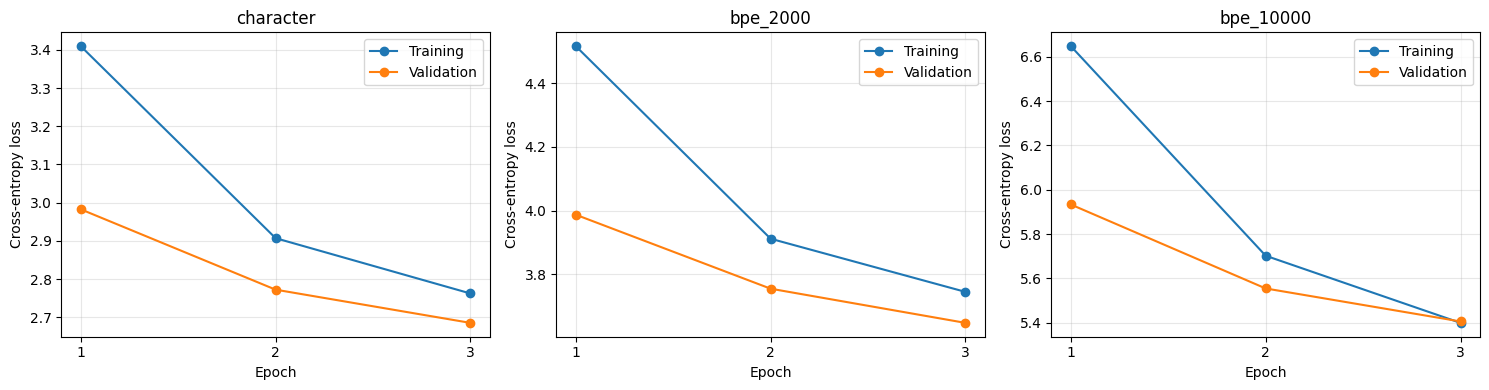

In [74]:
# Plot training and validation loss for each model
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, name in zip(axes, tokenizer_names):

    history = training_histories[name]
    epochs = range(1, len(history["train_loss"]) + 1)

    ax.plot(
        epochs,
        history["train_loss"],
        marker="o",
        label="Training"
    )

    ax.plot(
        epochs,
        history["valid_loss"],
        marker="o",
        label="Validation"
    )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-entropy loss")
    ax.set_xticks(list(epochs))
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()

# Save figure
plt.savefig(
    OUTPUT_DIR / "learning_curves.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

#### 5.3 Saved Model Verification

In [75]:
# Verify saved models and results
for name in tokenizer_names:
    path = OUTPUT_DIR / f"{name}_checkpoint.pt"
    print(f"{name}: {path.exists()}")

print("Training histories:",
      (OUTPUT_DIR / "training_histories.json").exists())

print("Parameter counts:",
      (OUTPUT_DIR / "parameter_counts.json").exists())

print("Learning curves:",
      (OUTPUT_DIR / "learning_curves.png").exists())

character: True
bpe_2000: True
bpe_10000: True
Training histories: True
Parameter counts: True
Learning curves: True


#### 5.4 Export Trained Model Weights

In [79]:
# Export trained model weights without optimizer states
for name in tokenizer_names:

    # Load the saved training checkpoint
    checkpoint = torch.load(
        OUTPUT_DIR / f"{name}_checkpoint.pt",
        map_location="cpu",
        weights_only=True
    )

    # Save only the model weights
    weights_path = OUTPUT_DIR / f"{name}_weights.pt"

    torch.save(
        checkpoint["model_state_dict"],
        weights_path
    )

    # Report file size
    size_mb = weights_path.stat().st_size / (1024 ** 2)

    print(f"{name}: {size_mb:.1f} MB")

character: 24.6 MB
bpe_2000: 10.1 MB
bpe_10000: 25.7 MB
